# Homework 5 (due 9 November 2026 23:59:59)
### PHYS 440/540, Fall 2026

## Problems 1

Complete Chapter 4 of the *dimensionality reduction* course in Data Camp.

## Problem 2

Do 1 more Data Camp chapters of your choice from within the following:
* Interactive Data Visualization with Bokeh
* Dimensionality reduction
* Introduction to Data Visualization in Python
* Introduction to Data Visualization with Matplotlib
* Introduction to Data Visualization with Seaborn
* Intermediate Data Visualization with Seaborn
* Data Visualization for Everyone

I'm not going to assign all of them as that will just cause confusion (in that you might think that I'm assigning 20 hours of work!).  So, you are just going to tell me which chapter you completed from among all the choices in this list of courses.  Do this by filling in the Course/Chapter title in the cell below.  Scroll through the course outlines first to see which ones look the most interesting/useful to you.

## Problem 3

1. Read in a sample of SDSS imaging data and create a mask to limit the data to "good" objects.  How many objects are left?  How many did you start with?

2. Print out the feature names, and create a data matrix, X, out of a subset of features for the "good" objects.

3. Use PCA (with randomized svd_solver for speed) to reduce the data matrix down to $2$ features. What is the explained variance of the data encapsulated in these eigen-features?

4. Access the `type` key of the `data` structure and make an array of labels out of these. 

5. Make a scatter plot of the PCA-reduced data, colored by their corresponding `type`. *(You may want to set the transparency to be lower than 1 to see the mixing of samples.)*

6. Choose $6000$ random integers between 0 and the number of samples in the data matrix. Record these integers because you'll use them later. 

7. Now try some non-linear dimensional reduction. These algorithms are slower than PCA, so you will operate only on the $6000$ random samples identified in the previous part. 
   - Try `LocallyLinearEmbedding`, `Isomap`, and `TSNE` algorithms, setting the number of components to be $2$ in all cases. 

8. As in the PCA case, make scatter plots of the dimensionally-reduced data, color coded by their `type`. For LLE and Isomap, experiment with the number of nearest neighbors between $5$ and $100$ to see what visually gives the best separation in `type` populations. For TSNE, do the same for the perplexity attribute. 

9. Which algorithm gives the cleanest way to visually see the two populations of sources? *(This will be subjective according to the samples you trained on, and even the randomness of the algorithms.)*

## Problem 1
* Dimensionlity Reduction

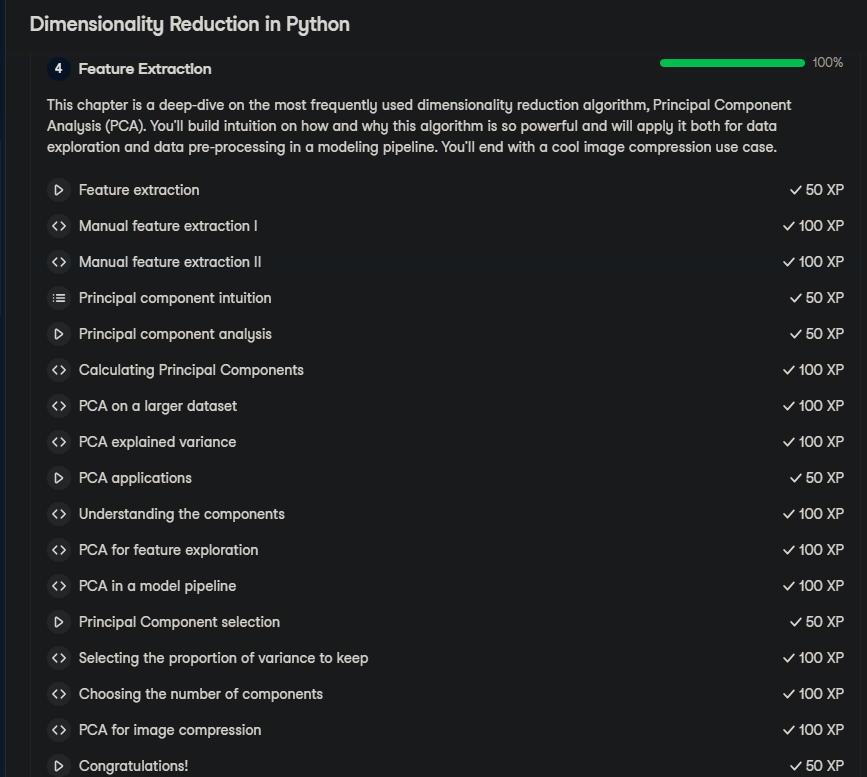

In [1]:
from IPython import display
display.Image("h5_1.png")

Chapters completed for Problem 2:
* Interactive Data Visualization with Bokeh

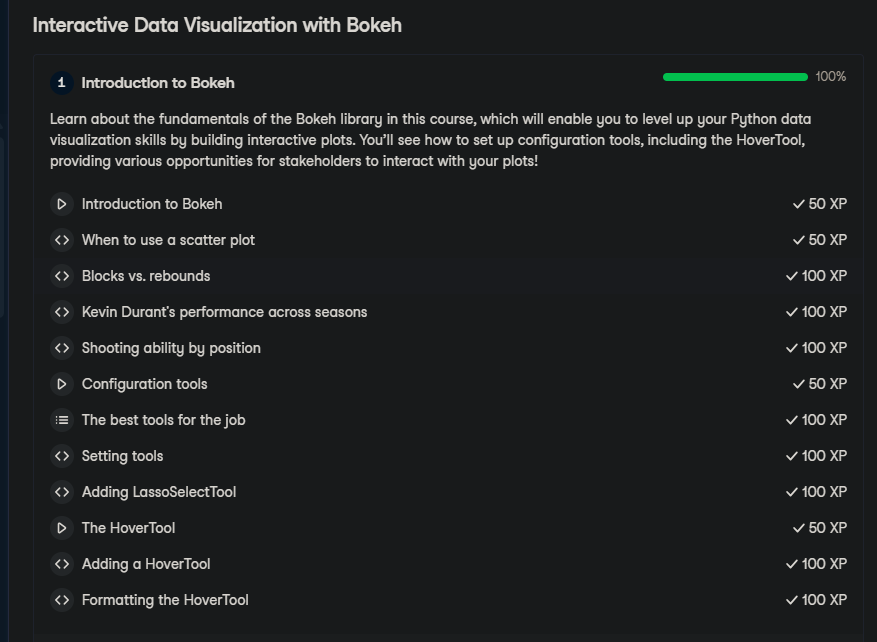

In [2]:
from IPython import display
display.Image("h5_2.png")

---
Problem 3 Starter Code

1. Read in a sample of SDSS imaging data. and create a mask to limit the data to "good" objects.  How many objects are left?  How many did you start with?

In [3]:
# Execute this cell
from matplotlib import pyplot as plt
import numpy as np
from astroML.datasets import fetch_imaging_sample
from sklearn.decomposition import PCA

In [4]:
data = fetch_imaging_sample()  
print(data.shape)  # number of objects in dataset

(330753,)


In [5]:
mask = ((data['iRaw']<21.0)&(data['uErr']<0.2)&(data['gErr']<0.2)&(data['rErr']<0.2)&(data['iErr']<0.2)&(data['zErr']<0.2))

In [6]:
data_good = data[mask]
print(len(data_good))

38673


Original started with 330,753 samples. After applying the mask, the data reduced to 38,673.

2. Print out the feature names, and create a data matrix, X, out of a subset of features for the "good" objects.

In [7]:
print(data.dtype.names)

('ra', 'dec', 'run', 'rExtSFD', 'uRaw', 'gRaw', 'rRaw', 'iRaw', 'zRaw', 'uErr', 'gErr', 'rErr', 'iErr', 'zErr', 'uRawPSF', 'gRawPSF', 'rRawPSF', 'iRawPSF', 'zRawPSF', 'upsfErr', 'gpsfErr', 'rpsfErr', 'ipsfErr', 'zpsfErr', 'type', 'ISOLATED')


In [8]:
keylist = ['rExtSFD', 'uRaw', 'gRaw', 'rRaw', 'iRaw', 'zRaw', \
           'uErr', 'gErr', 'rErr', 'iErr', 'zErr', \
           'uRawPSF', 'gRawPSF', 'rRawPSF', 'iRawPSF', 'zRawPSF', 
           'upsfErr', 'gpsfErr', 'rpsfErr', 'ipsfErr', 'zpsfErr']

In [9]:
X = np.column_stack([data_good[key] for key in keylist]) 
print(X)

[[1.1200e-01 2.0814e+01 1.9541e+01 ... 1.7000e-02 1.9000e-02 3.6000e-02]
 [1.1300e-01 2.0704e+01 1.8704e+01 ... 1.7000e-02 1.9000e-02 2.8000e-02]
 [1.0900e-01 1.7680e+01 1.6087e+01 ... 1.6000e-02 1.5000e-02 1.7000e-02]
 ...
 [7.4000e-02 2.1508e+01 2.0675e+01 ... 3.9000e-02 3.6000e-02 1.3300e-01]
 [7.5000e-02 2.1502e+01 2.0658e+01 ... 4.2000e-02 3.6000e-02 1.1000e-01]
 [7.6000e-02 2.1023e+01 2.0024e+01 ... 2.1000e-02 2.3000e-02 5.9000e-02]]


3. Use PCA (with randomized svd_solver for speed) to reduce the data matrix down to $2$ features. What is the explained variance of the data encapsulated in these eigen-features?

In [12]:
# use Randomized PCA for speed
pca = PCA(n_components=2, svd_solver='randomized')
X_reduced = pca.fit_transform(X)
evals = pca.explained_variance_ratio_
print(f'Expained fractional variance of data encapsulated in the eigenvalues: + {evals}')
print(f'Total explained variance: + {evals.sum():.4f} ({100 * evals.sum():.2f}%)')

Expained fractional variance of data encapsulated in the eigenvalues: + [0.88389627 0.06613403]
Total explained variance: + 0.9500 (95.00%)


4. Access the `type` key of the `data` structure and make an array of labels out of these. 

In [13]:
list(set(data_good['type']))
#Note one of these types refers to stars, the other to galaxies

[np.int16(3), np.int16(6)]

5. Make a scatter plot of the PCA-reduced data, colored by their corresponding `type`. *(You may want to set the transparency to be lower than 1 to see the mixing of samples.)*

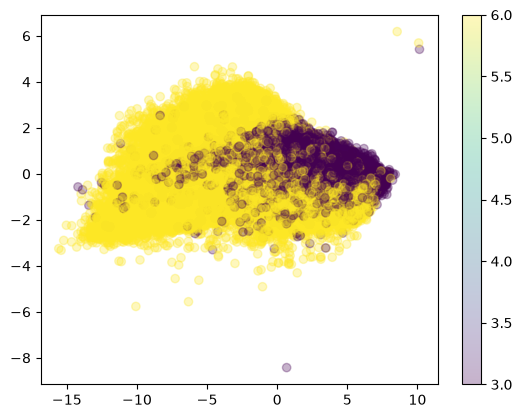

In [14]:
plt.scatter(X_reduced[:,0], X_reduced[:,1], c=data_good['type'], alpha=0.3)
plt.colorbar()
plt.show()

5. Choose $6000$ random integers between 0 and the number of samples in the data matrix. Record these integers because you'll use them later.

In [15]:
ind = np.random.randint(low=0,high=X.shape[0],size=6000)

6. Now try some non-linear dimensional reduction. These algorithms are slower than PCA, so you will operate only on the $6000$ random samples identified in the previous part. 
   - Try `LocallyLinearEmbedding`, `Isomap`, and `TSNE` algorithms, setting the number of components to be $2$ in all cases. 
   
7. As in the PCA case, make scatter plots of the dimensionally-reduced data, color coded by their `type`. For LLE and Isomap, experiment with the number of nearest neighbors between $5$ and $100$ to see what visually gives the best separation in `type` populations. For TSNE, do the same for the perplexity attribute. 

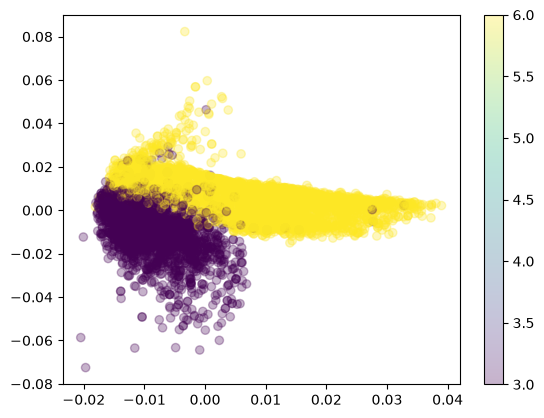

In [16]:
from sklearn.manifold import LocallyLinearEmbedding
k = 30 # Number of neighbors to use in fit
n = 2 # Number of dimensions to fit

lle = LocallyLinearEmbedding(n_neighbors=k,n_components=n)

X_reduced = lle.fit_transform(X[ind,:])

plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=data_good['type'][ind], alpha=0.3)
plt.colorbar()

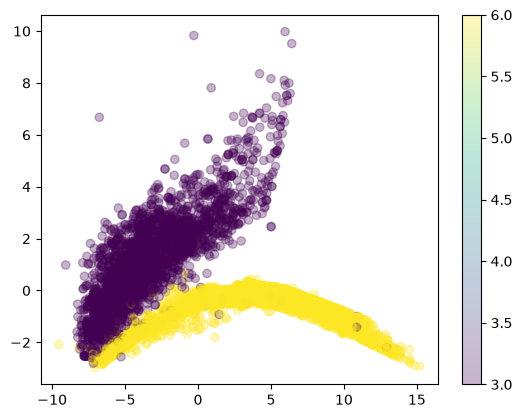

In [17]:
from sklearn.manifold import Isomap
k = 30
n = 2

iso = Isomap(n_neighbors=k, n_components=n)

X_reduced = iso.fit_transform(X[ind,:])

plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=data_good['type'][ind], alpha=0.3)
plt.colorbar()
plt.show()

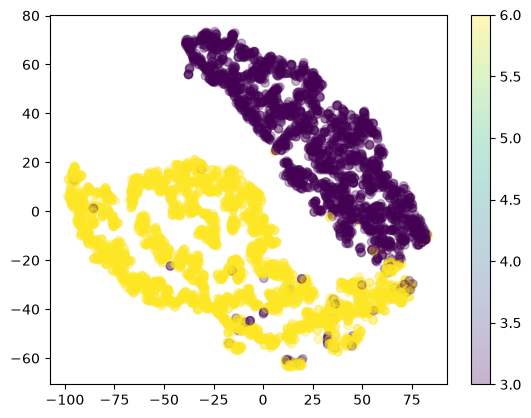

In [18]:
from sklearn.manifold import TSNE
n = 2

tsne = TSNE(n_components=n, perplexity=30)

X_reduced = tsne.fit_transform(X[ind,:])

plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=data_good['type'][ind], alpha=0.3)
plt.colorbar()
plt.show()


8. Which algorithm gives the cleanest way to visually see the two populations of sources? *(This will be subjective according to the samples you trained on, and even the randomness of the algorithms.)*

Any reasonable answer.

t-SNE gives the most cleanest plot out of all 3 algorithms. t-SNE gives clear clusters and has the least amount of overlap in the data. However, the results heavily depend on the training data that is provided to all of the algorithms. 